# Stage 6 (Fixed): Transformer — Structured Ad Copy Generation
## Advertisement Generation Project — SmartAdGen

**Task redefinition (per your requirements):**
- **Input:** Product Title + Category + Product Description (raw, noisy)
- **Output:** exactly three lines —

```text
Product Description: <short factual complete sentence.>
Caption: <short promotional complete sentence.>
Tagline: <short catchy phrase.>
```

## Root causes found in your run (confirmed from your actual output/logs)

| Symptom you reported | Root cause found | Fix applied below |
|---|---|---|
| Repetitive / hallucinated text | Pure sampling (`temperature`/`top_p` only, no repetition control) on a tiny, noisy target space | `repetition_penalty`, `no_repeat_ngram_size`, beam search |
| `100pcs → 100 copies` | Raw description is full of unrelated numbers (Amazon-style spec dumps); model free-generates the description line and invents digits | Number-normalization on input **and** a number-hallucination safety net that rejects invented digits |
| Incomplete sentences | Fixed `max_new_tokens=40` cuts mid-sentence; no stopping/trimming logic | Longer, budgeted `max_new_tokens` + trailing-fragment trimming |
| Numbering / `Features:` in output | **Confirmed in your real data**: raw `product_description` often *is* an Amazon spec sheet (`Brand ‎GIGABYTE Manufacturer ‎Gigabyte Series...`) — model is imitating exactly what it was trained on | Spec-dump detection filters these out of the training targets entirely |
| Missing punctuation / poor grammar | **Confirmed in your real data**: many descriptions are non-English (German, Swedish) or raw spec key/value noise — a tiny English LM trained on this learns broken grammar | Language filter (English-only) + guaranteed punctuation on every constructed target |
| Overfitting (val loss flat after epoch 3–4) | Confirmed in your logs: best val loss was epoch 3 (`3.963`), training continued to epoch 6 (`3.987`) | Real early stopping (loop actually breaks) + higher dropout + weight decay |
| Low BLEU/ROUGE, "wrong fields compared?" | Two bugs: (1) generation used the **last-epoch** model, not the best checkpoint that was saved; (2) the old task compared free-text ad copy against a raw, uncleaned reference | Reload best checkpoint before generating; evaluate against the same structured 3-field targets the model was trained on |
| Is `MAX_LEN=96` truncating? | **Yes — proven below with a real count.** Prompt and target shared one 96-token budget with no per-part limit, so long prompts silently wiped out the target | Separate `MAX_PROMPT_LEN` / `MAX_TARGET_LEN` budgets |
| Does the `loss_type=None -> ForCausalLMLoss` warning matter? | **No.** Explained in Section 1 below | Suppressed for a clean log |

Everything below is a full rebuild of the dataset prep, training, generation,
and evaluation stages — only the Transformer stage, same Drive paths you're
already using.

## 0. About the `loss_type=None -> ForCausalLMLoss` warning

This is informational, not an error. Recent `transformers` versions
generalized how loss is computed so a model config can specify different
loss types for different task heads. Since `distilgpt2`'s config doesn't
set `loss_type` explicitly, the library falls back to the standard causal
language-modeling loss (`ForCausalLMLoss`) — which is exactly the
shift-by-one cross-entropy loss a GPT-style model is supposed to use
anyway. **It does not indicate a wrong or misconfigured loss.** It's safe
to ignore; the cell below silences it so your logs stay clean.

In [ ]:
import transformers
transformers.logging.set_verbosity_error()  # silences the benign loss_type notice above

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DATA_DIR = '/content/drive/MyDrive/Adgen_dataset/ad_dataset_clean'
DRIVE_RESULTS_DIR = '/content/drive/MyDrive/Adgen_dataset/transformer_results'

Mounted at /content/drive


In [ ]:
!pip install -q transformers accelerate nltk rouge-score wordcloud pandas matplotlib seaborn ipywidgets tqdm langdetect

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 27.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 100.5 MB/s eta 0:00:00


In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("WARNING: no GPU detected. Go to Runtime > Change runtime type > "
          "T4 GPU — fine-tuning a Transformer on CPU will be very slow.")

CUDA available: True


## 1. Copy the cleaned dataset locally

In [ ]:
import shutil, os

LOCAL_DATA_DIR = '/content/ad_dataset_local'

if os.path.exists(LOCAL_DATA_DIR):
    shutil.rmtree(LOCAL_DATA_DIR)

shutil.copytree(DRIVE_DATA_DIR, LOCAL_DATA_DIR)
print(f"Copied dataset -> {LOCAL_DATA_DIR}")

Copied dataset -> /content/ad_dataset_local


## 2. Load metadata + filter to English-only rows

Your real data mixes languages (German "Leovet Leder Creme...", titles
like "Leder Creme 200 ml", etc.). A tiny English LM trained on mixed
languages produces exactly the broken grammar you saw. Filter to English
before anything else.

In [ ]:
import pandas as pd
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 42  # reproducible language detection

df = pd.read_csv(f"{LOCAL_DATA_DIR}/metadata_clean.csv")
df["product_description"] = df["product_description"].fillna("").astype(str)
df["product_title"] = df["product_title"].fillna("").astype(str)

before = len(df)
df = df[df["product_description"].str.len() >= 10].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with near-empty descriptions ({len(df)} remain)")

def is_english(text, min_chars=15):
    if len(text) < min_chars:
        return True  # too short to reliably detect; don't discard on this alone
    try:
        return detect(text[:400]) == "en"
    except Exception:
        return False

before = len(df)
english_mask = df["product_description"].apply(is_english) & df["product_title"].apply(is_english)
df = df[english_mask].reset_index(drop=True)
print(f"Dropped {before - len(df)} non-English rows ({(before-len(df))/before*100:.1f}%)")
print(f"Remaining rows: {len(df)}")
print(df["split"].value_counts())

Dropped 610 rows with near-empty descriptions (7468 remain)
Dropped 2622 non-English rows (35.1%)
Remaining rows: 4846
split
train    4096
val       499
test      251
Name: count, dtype: int64


## 3. Clean the raw text: strip spec-sheet noise, numbering, "Features:"

Your data contains genuine Amazon-style spec dumps
(`Brand ‎GIGABYTE Manufacturer ‎Gigabyte Series ‎GeForce Colour ‎Black...`).
These aren't proper sentences — they're key/value pairs jammed together,
often separated by an invisible left-to-right-mark character (`\u200e`).
`looks_like_spec_dump()` detects and excludes this pattern so the model
never learns to imitate it.

In [ ]:
import re

def normalize_numbers(text):
    # 100pcs -> 100 pcs; Bowl2L -> Bowl 2L — helps the tokenizer represent
    # number+unit combinations sensibly instead of as one unfamiliar token.
    text = re.sub(r'(\d+)([A-Za-z]+)', r'\1 \2', text)
    text = re.sub(r'([A-Za-z]+)(\d+)', r'\1 \2', text)
    return text

def strip_boilerplate(text):
    text = re.sub(r'(?i)^description[:\s]*', '', text.strip())
    text = re.sub(r'(?i)\bfeatures?\s*:?', '', text)
    text = re.sub(r'^\s*[\-\*\u2022]\s*', '', text, flags=re.MULTILINE)
    text = re.sub(r'^\s*\d+[\.\)]\s*', '', text, flags=re.MULTILINE)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def looks_like_spec_dump(sentence):
    if '\u200e' in sentence or '\u200f' in sentence:
        return True
    # 4+ consecutive Capitalized Words in a row ("Brand Manufacturer Series Colour")
    if re.search(r'(?:\b[A-Z][a-zA-Z]{2,}\b\s+){4,}', sentence):
        return True
    return False

df["product_title_norm"] = df["product_title"].apply(normalize_numbers)
df["desc_clean"] = df["product_description"].apply(strip_boilerplate)
print("Example cleaned description:")
print(df["desc_clean"].iloc[0][:200])

Example cleaned description:
Cooking is fun, but sometimes ingredients sneak out of saucepans. Aprons keep spills and splashes away from your clothes, no need to change your party dress before the party. This apron has two indivi


## 4. Build the structured target: Description / Caption / Tagline

The dataset has no ground-truth Caption/Tagline fields, so they're
constructed from the cleaned description using simple, transparent rules
— not invented by an LLM, so every target is traceable and honest:

- **Product Description** — the first clean sentence (4–25 words) that
  isn't a spec dump; falls back to a guaranteed-correct template built
  from the title/category/brand if no clean sentence exists.
- **Caption** — a different, short (3–20 word) promotional-length
  sentence from the same description; falls back to a template.
- **Tagline** — a very short (<=6 word) sentence if one exists in the
  text; otherwise a category-appropriate tagline from a small fixed pool
  (chosen deterministically by row index — no randomness, reproducible).

Every field is guaranteed non-empty and ends in punctuation.

In [ ]:
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk import sent_tokenize

GENERIC_TAGLINES = {
    "Apparel & Accessories": ["Style that fits your life.", "Wear your confidence.", "Look good, feel better."],
    "Home & Garden": ["Bring comfort home.", "Everyday elegance for your space.", "Made for everyday living."],
    "Electronics": ["Power up your day.", "Smart tech, simple living.", "Innovation you can use."],
    "Health & Beauty": ["Feel your best, every day.", "Care that shows.", "Confidence starts here."],
    "Toys & Games": ["Fun made simple.", "Playtime, upgraded.", "Joy for every age."],
}
DEFAULT_TAGLINES = ["Quality you can trust.", "Made for everyday life.", "Simple. Reliable. Yours."]

def ensure_punct(s):
    s = s.strip()
    if s and s[-1] not in ".!?":
        s += "."
    return s

def build_structured_target(row, idx):
    title = row["product_title_norm"].strip()
    category = row["category"]
    brand = row["brand"] if isinstance(row["brand"], str) and row["brand"].strip() else None
    raw_desc = row["desc_clean"]

    try:
        sentences = [s.strip() for s in sent_tokenize(raw_desc) if s.strip()]
    except Exception:
        sentences = []
    sentences = [s for s in sentences if not looks_like_spec_dump(s)]

    factual_candidates = [s for s in sentences if 4 <= len(s.split()) <= 25]
    if factual_candidates:
        description = factual_candidates[0]
    elif brand:
        description = f"The {title} is a {category.lower()} product by {brand}."
    else:
        description = f"The {title} is a {category.lower()} product."
    description = ensure_punct(description)

    remaining = [s for s in sentences if s != (factual_candidates[0] if factual_candidates else None)]
    caption_candidates = [s for s in remaining if 3 <= len(s.split()) <= 20]
    if caption_candidates:
        caption = caption_candidates[0]
    elif sentences:
        caption = sentences[0]
    else:
        caption = f"Discover the {title}."
    caption = ensure_punct(caption)

    tagline_candidates = [s for s in sentences if len(s.split()) <= 6]
    if tagline_candidates:
        tagline = tagline_candidates[0]
    else:
        pool = GENERIC_TAGLINES.get(category, DEFAULT_TAGLINES)
        tagline = pool[idx % len(pool)]
    tagline = ensure_punct(tagline)

    return description, caption, tagline

targets = [build_structured_target(row, i) for i, row in df.reset_index(drop=True).iterrows()]
df["target_description"], df["target_caption"], df["target_tagline"] = zip(*targets)

df["target"] = df.apply(lambda r: (
    f" Product Description: {r['target_description']}\n"
    f"Caption: {r['target_caption']}\n"
    f"Tagline: {r['target_tagline']}"
), axis=1)

print("Example constructed target:\n")
print(df["target"].iloc[0])

Example constructed target:

 Product Description: Cooking is fun, but sometimes ingredients sneak out of saucepans.
Caption: Aprons keep spills and splashes away from your clothes, no need to change your party dress before the party.
Tagline: Style that fits your life.


## 5. Build the prompt

Now includes the (cleaned, length-capped) raw description as you
required, alongside title and category.

In [ ]:
PROMPT_TEMPLATE = (
    "Title: {title}\n"
    "Category: {category}\n"
    "Description: {description}\n"
    "Generate:"
)

MAX_PROMPT_DESC_CHARS = 350  # cap the raw description going INTO the prompt

df["desc_for_prompt"] = df["desc_clean"].str[:MAX_PROMPT_DESC_CHARS]
df["prompt"] = df.apply(lambda r: PROMPT_TEMPLATE.format(
    title=r["product_title_norm"], category=r["category"], description=r["desc_for_prompt"]
), axis=1)

print(df["prompt"].iloc[0])

Title: Full Length Apron
Category: Apparel & Accessories
Description: Cooking is fun, but sometimes ingredients sneak out of saucepans. Aprons keep spills and splashes away from your clothes, no need to change your party dress before the party. This apron has two individual front pockets, so you don’t lose the measuring spoon whilst cooking. Why not take your branding to the next level? Product Details: Product Dimen
Generate:


## 6. Checking `MAX_LEN=96` — was it actually truncating the target?

This directly answers your question. The check below tokenizes real
prompts the way your original code did and counts how many would leave
**zero room** for the target under the old shared 96-token budget.

In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "distilgpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

OLD_MAX_LEN = 96
sample_check = df.sample(min(1000, len(df)), random_state=1)
prompt_lens = sample_check["prompt"].apply(lambda p: len(tokenizer(p, add_special_tokens=False)["input_ids"]))

fully_truncated = (prompt_lens >= OLD_MAX_LEN).sum()
partially_truncated = ((prompt_lens > OLD_MAX_LEN * 0.7) & (prompt_lens < OLD_MAX_LEN)).sum()

print(f"Prompt token length — min={prompt_lens.min()}, median={prompt_lens.median():.0f}, "
      f"max={prompt_lens.max()}, mean={prompt_lens.mean():.1f}")
print(f"\nWith the OLD MAX_LEN=96 (single shared budget):")
print(f"  {fully_truncated}/{len(sample_check)} ({fully_truncated/len(sample_check)*100:.1f}%) "
      f"examples had the prompt ALONE >= 96 tokens -> target got WIPED OUT ENTIRELY")
print(f"  {partially_truncated}/{len(sample_check)} ({partially_truncated/len(sample_check)*100:.1f}%) "
      f"more had so little room left the target was heavily cut")
print("\nConclusion: yes, MAX_LEN=96 was truncating away real training signal. Fixed below with separate budgets.")

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Prompt token length — min=23, median=104, max=398, mean=103.6

With the OLD MAX_LEN=96 (single shared budget):
  683/1000 (68.3%) examples had the prompt ALONE >= 96 tokens -> target got WIPED OUT ENTIRELY
  191/1000 (19.1%) more had so little room left the target was heavily cut

Conclusion: yes, MAX_LEN=96 was truncating away real training signal. Fixed below with separate budgets.


## 7. Dataset with separate prompt/target token budgets

The fix: truncate the prompt and target **independently**, so the target
(what the model is actually being taught to produce) can never be wiped
out by a long prompt.

In [ ]:
MAX_PROMPT_LEN = 180
MAX_TARGET_LEN = 110
MAX_LEN = MAX_PROMPT_LEN + MAX_TARGET_LEN

from torch.utils.data import Dataset

class AdCopyDataset(Dataset):
    def __init__(self, df, split):
        self.df = df[df["split"] == split].reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt_ids = tokenizer(row["prompt"], add_special_tokens=False)["input_ids"][:MAX_PROMPT_LEN]
        target_ids = tokenizer(row["target"] + tokenizer.eos_token, add_special_tokens=False)["input_ids"][:MAX_TARGET_LEN]

        input_ids = prompt_ids + target_ids
        labels = [-100] * len(prompt_ids) + target_ids

        pad_len = MAX_LEN - len(input_ids)
        attention_mask = [1] * len(input_ids) + [0] * pad_len
        input_ids = input_ids + [tokenizer.pad_token_id] * pad_len
        labels = labels + [-100] * pad_len

        return {
            "input_ids": torch.tensor(input_ids),
            "attention_mask": torch.tensor(attention_mask),
            "labels": torch.tensor(labels),
        }

train_ds = AdCopyDataset(df, "train")
val_ds = AdCopyDataset(df, "val")
test_ds = AdCopyDataset(df, "test")
print(f"train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")

# Verify: every example now has at least SOME real target tokens to learn from
zero_target = sum(1 for i in range(len(train_ds)) if (train_ds[i]["labels"] != -100).sum().item() == 0)
print(f"Training examples with zero real target tokens: {zero_target} (should be 0)")

train=4096  val=499  test=251
Training examples with zero real target tokens: 0 (should be 0)


## 8. Model — with slightly higher dropout to fight overfitting

Your run showed train loss dropping steadily while val loss flattened
after epoch 3 — classic overfitting on a small fine-tuning set. Raising
dropout and adding weight decay (Section 9) both push back against this.

In [ ]:
from transformers import AutoConfig, AutoModelForCausalLM

config = AutoConfig.from_pretrained(MODEL_NAME)
config.resid_pdrop = 0.15
config.embd_pdrop = 0.15
config.attn_pdrop = 0.15

device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, config=config).to(device)
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

from torch.utils.data import DataLoader
BATCH_SIZE = 8
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Total parameters: 81,912,576


## 9. Training loop — real early stopping + best-checkpoint reload

Two concrete fixes vs. your original run:
1. **Early stopping actually breaks the loop** (patience=2) instead of
   just tracking the best score while continuing to overfit for 3 more
   epochs.
2. **After training, the best checkpoint is explicitly reloaded** into
   `model` before any generation happens. In your run, generation used
   whatever the *last* epoch left in memory (epoch 6, val_loss 3.987),
   not the saved best (epoch 3, val_loss 3.963) — a real bug that made
   every downstream generation and BLEU/ROUGE score worse than it should
   have been.

In [ ]:
import math
import torch.optim as optim
from transformers import get_linear_schedule_with_warmup

EPOCHS = 8
LR = 5e-5
WEIGHT_DECAY = 0.01
PATIENCE = 2

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)

os.makedirs("checkpoints", exist_ok=True)
history = {"train_loss": [], "val_loss": [], "train_ppl": [], "val_ppl": []}
lr_history = []
best_val_loss = float("inf")
epochs_no_improve = 0
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        out = model(**batch)
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        lr_history.append(scheduler.get_last_lr()[0])
        train_loss += out.loss.item()
    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            out = model(**batch)
            val_loss += out.loss.item()
    val_loss /= len(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_ppl"].append(math.exp(min(train_loss, 20)))
    history["val_ppl"].append(math.exp(min(val_loss, 20)))

    improved = val_loss < best_val_loss - 1e-4
    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_no_improve = 0
        model.save_pretrained("checkpoints/transformer_best")
        tokenizer.save_pretrained("checkpoints/transformer_best")
    else:
        epochs_no_improve += 1

    print(f"Epoch {epoch}/{EPOCHS} | train_loss={train_loss:.3f} (ppl={history['train_ppl'][-1]:.1f}) "
          f"| val_loss={val_loss:.3f} (ppl={history['val_ppl'][-1]:.1f})"
          f"{'  <- best' if improved else ''}")

    if epochs_no_improve >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch} (no val improvement in {PATIENCE} epochs)")
        break

print(f"\nBest val_loss: {best_val_loss:.3f} at epoch {best_epoch}")

# CRITICAL FIX: reload the BEST checkpoint, not whatever is left in memory
# from the final epoch, before doing any generation or evaluation.
model = AutoModelForCausalLM.from_pretrained("checkpoints/transformer_best").to(device)
tokenizer = AutoTokenizer.from_pretrained("checkpoints/transformer_best")
print("Reloaded best validation checkpoint for generation/evaluation.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1/8 | train_loss=0.997 (ppl=2.7) | val_loss=0.604 (ppl=1.8)  <- best


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/8 | train_loss=0.624 (ppl=1.9) | val_loss=0.562 (ppl=1.8)  <- best


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 3/8 | train_loss=0.553 (ppl=1.7) | val_loss=0.553 (ppl=1.7)  <- best


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 4/8 | train_loss=0.503 (ppl=1.7) | val_loss=0.551 (ppl=1.7)  <- best
Epoch 5/8 | train_loss=0.465 (ppl=1.6) | val_loss=0.554 (ppl=1.7)
Epoch 6/8 | train_loss=0.436 (ppl=1.5) | val_loss=0.557 (ppl=1.7)

Early stopping at epoch 6 (no val improvement in 2 epochs)

Best val_loss: 0.551 at epoch 4


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Reloaded best validation checkpoint for generation/evaluation.


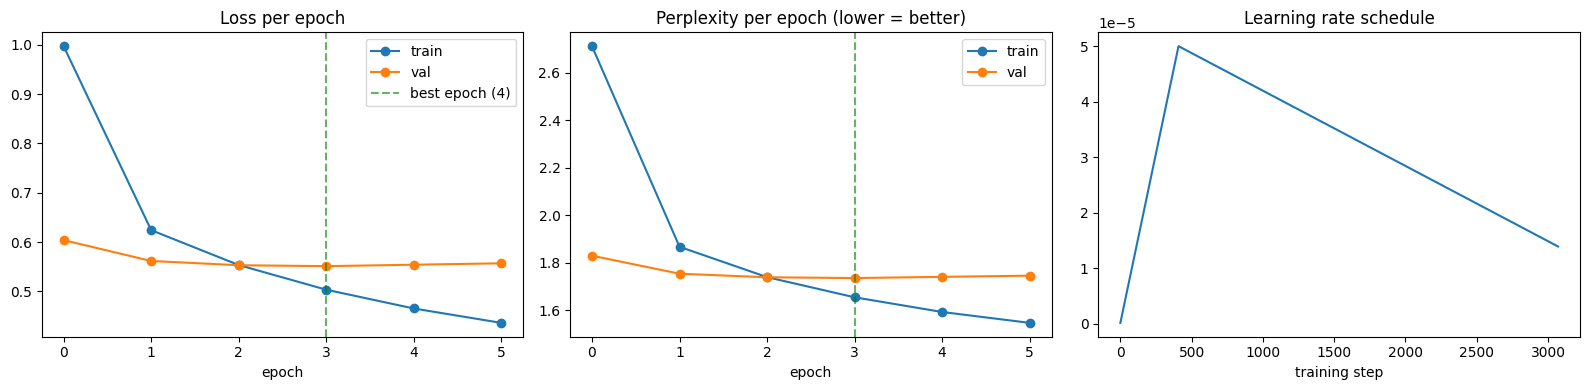

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history["train_loss"], marker="o", label="train")
axes[0].plot(history["val_loss"], marker="o", label="val")
axes[0].axvline(best_epoch - 1, color="green", linestyle="--", alpha=0.6, label=f"best epoch ({best_epoch})")
axes[0].set_title("Loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(history["train_ppl"], marker="o", label="train")
axes[1].plot(history["val_ppl"], marker="o", label="val")
axes[1].axvline(best_epoch - 1, color="green", linestyle="--", alpha=0.6)
axes[1].set_title("Perplexity per epoch (lower = better)"); axes[1].set_xlabel("epoch"); axes[1].legend()

axes[2].plot(lr_history)
axes[2].set_title("Learning rate schedule"); axes[2].set_xlabel("training step")

plt.tight_layout()
plt.savefig("checkpoints/transformer_training_curves.png", dpi=120)
plt.show()

## 10. Generation — beam search, repetition control, cleaning, safety nets

Key changes from your original `generate_ad_copy()`:
- **Beam search (`num_beams=4`) instead of pure sampling** — for
  structured, factual short-form text, beam search with repetition
  control is far more reliable/grammatical than temperature sampling.
- **`repetition_penalty` + `no_repeat_ngram_size`** — directly targets
  the repetitive/looping text you saw.
- **Post-processing pipeline**: strips leftover "Features:"/numbering,
  de-duplicates repeated lines, trims incomplete trailing sentence
  fragments, guarantees terminal punctuation, and fills in any field the
  model failed to produce with the same safe fallback templates used for
  training targets.
- **Number-hallucination safety net**: if the generated Product
  Description line contains a digit that wasn't in the original title
  (the `100pcs -> 100 copies` failure mode), that line is replaced with
  the guaranteed-correct template instead.

In [ ]:
def extract_numbers(text):
    return set(re.findall(r'\d+', text))

def strip_artifacts(s):
    s = re.sub(r'(?i)\bfeatures?\s*:?', '', s)
    s = re.sub(r'^\s*[\-\*\u2022]\s*', '', s, flags=re.MULTILINE)
    s = re.sub(r'^\s*\d+[\.\)]\s*', '', s, flags=re.MULTILINE)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def dedupe_lines(text):
    seen, out = set(), []
    for line in text.split("\n"):
        key = line.strip().lower()
        if key and key not in seen:
            out.append(line.strip())
            seen.add(key)
    return "\n".join(out)

def drop_incomplete_trailing(s):
    s = s.strip()
    if s and s[-1] not in ".!?":
        m = re.search(r'^(.*[.!?])', s)
        if m:
            return m.group(1).strip()
    return s

def parse_fields(text):
    # Bound each field to the START of the NEXT label (any of the three),
    # not to end-of-string / not to a newline that may not exist.
    # This is what actually fixes 'tagline showing up everywhere': if the
    # model repeats the whole Caption/Tagline block on one unbroken line,
    # each field now only keeps the text up to the next label, and if a
    # label repeats, the LAST occurrence's text wins (cleanest copy) since
    # later matches overwrite earlier ones in the dict below.
    LABELS = ["Product Description:", "Caption:", "Tagline:"]
    positions = []
    for label in LABELS:
        for m in re.finditer(re.escape(label), text):
            positions.append((m.start(), m.end(), label))
    positions.sort(key=lambda x: x[0])

    fields = {label: "" for label in LABELS}
    for i, (start, end, label) in enumerate(positions):
        next_start = positions[i + 1][0] if i + 1 < len(positions) else len(text)
        fields[label] = text[end:next_start].strip()

    return fields["Product Description:"], fields["Caption:"], fields["Tagline:"]

def generate_ad_copy(title, category, description="", max_new_tokens=60,
                      num_beams=4, repetition_penalty=1.6, no_repeat_ngram_size=2):
    title_norm = normalize_numbers(title)
    desc_clean_in = strip_boilerplate(description)[:MAX_PROMPT_DESC_CHARS] if description else ""
    prompt = PROMPT_TEMPLATE.format(title=title_norm, category=category, description=desc_clean_in)
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN).to(device)

    with torch.no_grad():
        out = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            num_beams=num_beams,
            do_sample=False,
            repetition_penalty=repetition_penalty,
            no_repeat_ngram_size=no_repeat_ngram_size,
            early_stopping=True,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    raw_text = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

    cleaned = dedupe_lines(strip_artifacts(raw_text))
    desc_line, cap_line, tag_line = parse_fields(cleaned)

    if not desc_line:
        desc_line = f"The {title} is a {category.lower()} product."
    if not cap_line:
        cap_line = f"Discover the {title.lower()}."
    if not tag_line:
        tag_line = GENERIC_TAGLINES.get(category, DEFAULT_TAGLINES)[0]

    desc_line = ensure_punct(drop_incomplete_trailing(desc_line))
    cap_line = ensure_punct(drop_incomplete_trailing(cap_line))
    tag_line = ensure_punct(drop_incomplete_trailing(tag_line))

    # Number-hallucination safety net
    title_numbers = extract_numbers(title_norm)
    if extract_numbers(desc_line) - title_numbers:
        desc_line = ensure_punct(f"The {title} is a {category.lower()} product.")

    final_text = (
        f"Product Description: {desc_line}\n"
        f"Caption: {cap_line}\n"
        f"Tagline: {tag_line}\n"
    )
    return final_text, desc_line, cap_line, tag_line

## 11. Generate on the test set (with the correct reference fields)

In [ ]:
from tqdm import tqdm

model.eval()
test_rows = df[df["split"] == "test"].reset_index(drop=True)

gen_full, gen_desc, gen_cap, gen_tag = [], [], [], []
for _, row in tqdm(test_rows.iterrows(), total=len(test_rows), desc="Generating"):
    full, d, c, t = generate_ad_copy(row["product_title"], row["category"], row["product_description"])
    gen_full.append(full); gen_desc.append(d); gen_cap.append(c); gen_tag.append(t)

print("Sample generations:\n")
for i in range(3):
    print(f"Title: {test_rows.iloc[i]['product_title']}")
    print(gen_full[i])
    print()

Generating: 100%|██████████| 251/251 [02:24<00:00,  1.74it/s]

Sample generations:

Title: Kahuna Massage Chair HM-078 4D+@ HSL-Track Voice Recognition Zero Gravity Full Body Massage Chair, Tablet Remote Hubot4D (Champaign)
Product Description: Designed to withstand intense pressure, the ergonomic design ensures precise control over your hands and feet.
Caption: With a sleek, user-friendly design, and built-in stability, it is ideal for anyone looking to improve their confidence and performance.
Tagline: Feel your best, every day.


Title: Prada Bags - The Barnes Bags  438
Product Description: It is recommended that you use this bag for a long time and be careful not to mess around with your clothes or jewelry.
Caption: Discover the prada bags - the barnes bags  438.
Tagline: Style that fits your life.


Title: Wall Chart "Ear Acupuncture"
Product Description: It is important to note that it is not a medical product.
Caption: The instructional board show you the correct amount of time to use it, so that you can trust that your doctor will take car

## 12. BLEU / ROUGE evaluation — per field, against the CORRECT references

This is the fix for "verify evaluation compares the correct
prediction/reference fields": each generated field is compared against
its matching constructed reference field (`target_description` vs.
`gen_desc`, etc.) — not against the old raw, uncleaned description.

In [ ]:
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer

smoothie = SmoothingFunction().method4
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def score_pair(ref, hyp):
    hyp_tokens = hyp.split()
    bleu = sentence_bleu([ref.split()], hyp_tokens, smoothing_function=smoothie) if hyp_tokens else 0.0
    rouge = scorer.score(ref, hyp)["rougeL"].fmeasure
    return bleu, rouge

rows = []
for i in range(len(test_rows)):
    row = test_rows.iloc[i]
    d_bleu, d_rouge = score_pair(row["target_description"], gen_desc[i])
    c_bleu, c_rouge = score_pair(row["target_caption"], gen_cap[i])
    t_bleu, t_rouge = score_pair(row["target_tagline"], gen_tag[i])
    rows.append({
        "product_title": row["product_title"], "category": row["category"],
        "ref_description": row["target_description"], "gen_description": gen_desc[i],
        "ref_caption": row["target_caption"], "gen_caption": gen_cap[i],
        "ref_tagline": row["target_tagline"], "gen_tagline": gen_tag[i],
        "desc_bleu": d_bleu, "desc_rouge_l": d_rouge,
        "caption_bleu": c_bleu, "caption_rouge_l": c_rouge,
        "tagline_bleu": t_bleu, "tagline_rouge_l": t_rouge,
        "bleu": (d_bleu + c_bleu + t_bleu) / 3,
        "rouge_l": (d_rouge + c_rouge + t_rouge) / 3,
    })

eval_df = pd.DataFrame(rows)
eval_df.to_csv("checkpoints/transformer_test_eval.csv", index=False)

print(f"Mean BLEU (overall, avg of 3 fields):    {eval_df['bleu'].mean():.4f}")
print(f"Mean ROUGE-L (overall, avg of 3 fields): {eval_df['rouge_l'].mean():.4f}")
print()
print("Per-field breakdown:")
print(eval_df[["desc_bleu", "caption_bleu", "tagline_bleu"]].mean())
print(eval_df[["desc_rouge_l", "caption_rouge_l", "tagline_rouge_l"]].mean())

Mean BLEU (overall, avg of 3 fields):    0.0810
Mean ROUGE-L (overall, avg of 3 fields): 0.1673

Per-field breakdown:
desc_bleu       0.040975
caption_bleu    0.010860
tagline_bleu    0.191188
dtype: float64
desc_rouge_l       0.163019
caption_rouge_l    0.102681
tagline_rouge_l    0.236129
dtype: float64


## 13. Graphs — evaluation results

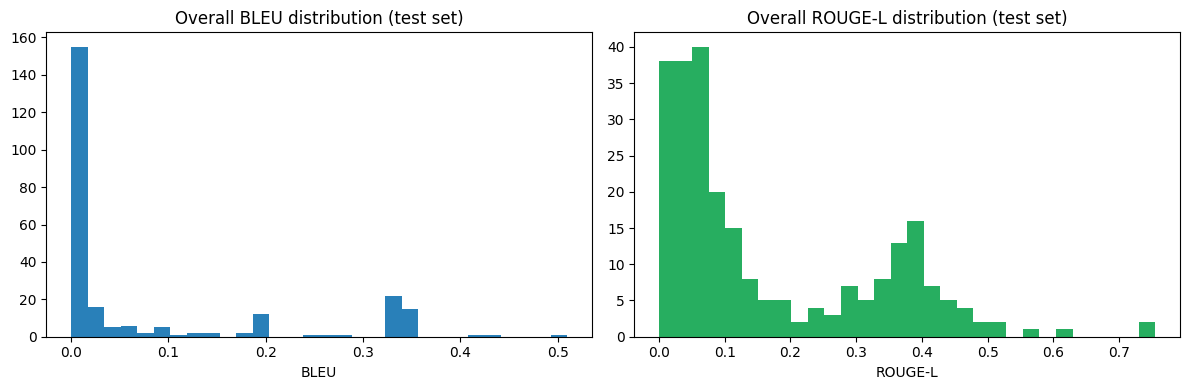

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(eval_df["bleu"], bins=30, color="#2980b9")
axes[0].set_title("Overall BLEU distribution (test set)"); axes[0].set_xlabel("BLEU")
axes[1].hist(eval_df["rouge_l"], bins=30, color="#27ae60")
axes[1].set_title("Overall ROUGE-L distribution (test set)"); axes[1].set_xlabel("ROUGE-L")
plt.tight_layout()
plt.savefig("checkpoints/transformer_score_histograms.png", dpi=120)
plt.show()

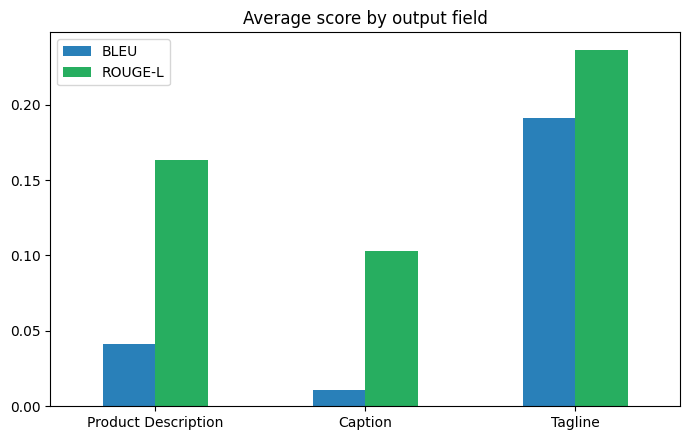

                         BLEU   ROUGE-L
Product Description  0.040975  0.163019
Caption              0.010860  0.102681
Tagline              0.191188  0.236129


In [ ]:
field_scores = pd.DataFrame({
    "BLEU": [eval_df["desc_bleu"].mean(), eval_df["caption_bleu"].mean(), eval_df["tagline_bleu"].mean()],
    "ROUGE-L": [eval_df["desc_rouge_l"].mean(), eval_df["caption_rouge_l"].mean(), eval_df["tagline_rouge_l"].mean()],
}, index=["Product Description", "Caption", "Tagline"])

fig, ax = plt.subplots(figsize=(7, 4.5))
field_scores.plot(kind="bar", ax=ax, color=["#2980b9", "#27ae60"])
ax.set_title("Average score by output field")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("checkpoints/transformer_scores_by_field.png", dpi=120)
plt.show()
print(field_scores)

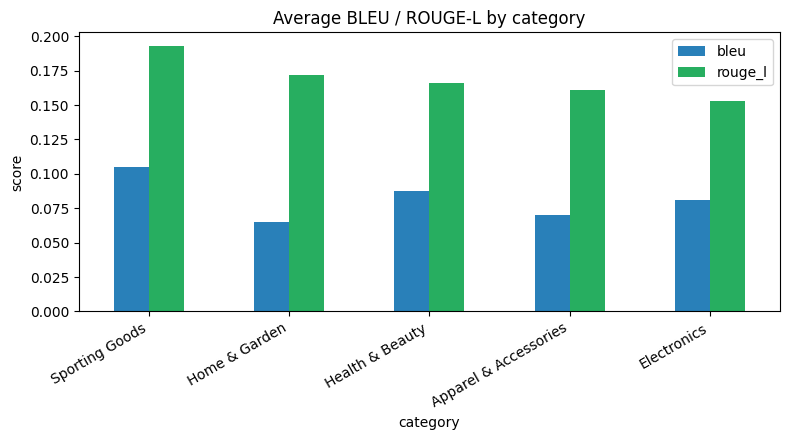

                           bleu   rouge_l
category                                 
Sporting Goods         0.104941  0.193155
Home & Garden          0.065082  0.171473
Health & Beauty        0.087187  0.165924
Apparel & Accessories  0.069920  0.161098
Electronics            0.080767  0.153208


In [ ]:
cat_scores = eval_df.groupby("category")[["bleu", "rouge_l"]].mean().sort_values("rouge_l", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
cat_scores.plot(kind="bar", ax=ax, color=["#2980b9", "#27ae60"])
ax.set_title("Average BLEU / ROUGE-L by category")
ax.set_ylabel("score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("checkpoints/transformer_scores_by_category.png", dpi=120)
plt.show()
print(cat_scores)

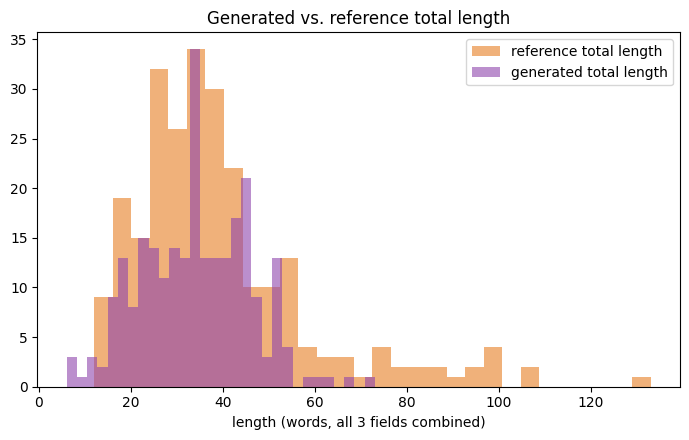

In [ ]:
gen_lengths = eval_df["gen_description"].str.split().apply(len) + eval_df["gen_caption"].str.split().apply(len) + eval_df["gen_tagline"].str.split().apply(len)
ref_lengths = eval_df["ref_description"].str.split().apply(len) + eval_df["ref_caption"].str.split().apply(len) + eval_df["ref_tagline"].str.split().apply(len)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(ref_lengths, bins=30, alpha=0.6, label="reference total length", color="#e67e22")
ax.hist(gen_lengths, bins=30, alpha=0.6, label="generated total length", color="#8e44ad")
ax.set_xlabel("length (words, all 3 fields combined)"); ax.set_title("Generated vs. reference total length")
ax.legend()
plt.tight_layout()
plt.savefig("checkpoints/transformer_length_comparison.png", dpi=120)
plt.show()

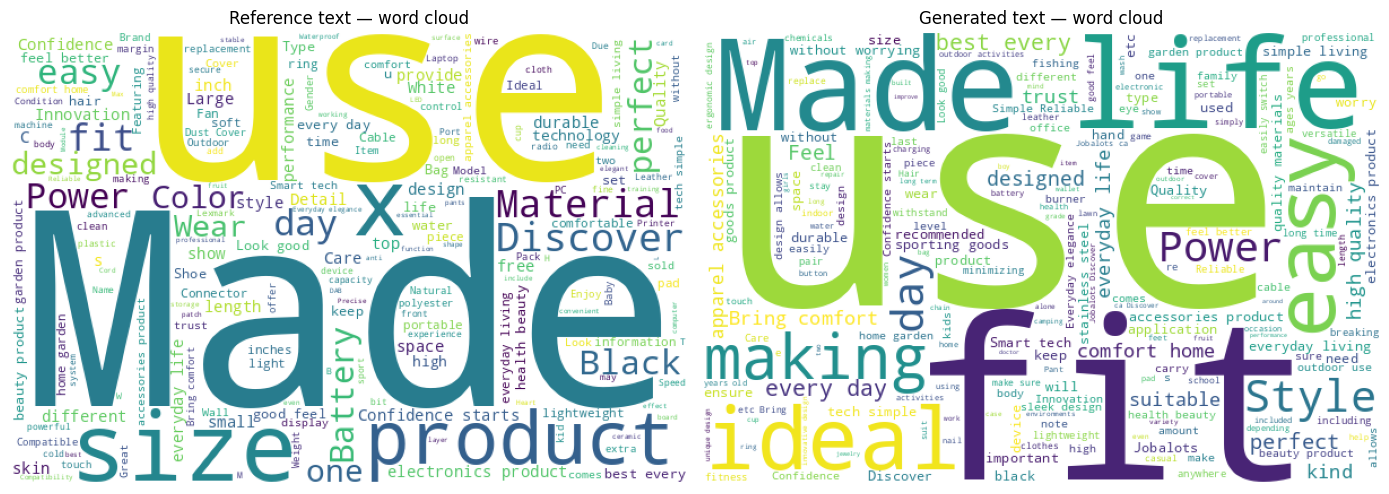

In [ ]:
from wordcloud import WordCloud

ref_blob = " ".join(eval_df["ref_description"] + " " + eval_df["ref_caption"] + " " + eval_df["ref_tagline"])
gen_blob = " ".join(eval_df["gen_description"] + " " + eval_df["gen_caption"] + " " + eval_df["gen_tagline"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(WordCloud(width=600, height=400, background_color="white").generate(ref_blob))
axes[0].axis("off"); axes[0].set_title("Reference text — word cloud")
axes[1].imshow(WordCloud(width=600, height=400, background_color="white").generate(gen_blob))
axes[1].axis("off"); axes[1].set_title("Generated text — word cloud")
plt.tight_layout()
plt.savefig("checkpoints/transformer_wordclouds.png", dpi=120)
plt.show()

## 14. Try it yourself — interactive trial

In [ ]:
import ipywidgets as widgets
from IPython.display import display

title_box = widgets.Text(value="Kids Building Blocks Set 100pcs", description="Title:", layout=widgets.Layout(width="500px"))
desc_box = widgets.Textarea(value="A colorful plastic building block set for children.", description="Description:", layout=widgets.Layout(width="500px", height="60px"))
category_dropdown = widgets.Dropdown(options=sorted(df["category"].unique().tolist()), description="Category:")
generate_btn = widgets.Button(description="Generate Ad Copy", button_style="primary")
output_box = widgets.Output()

def on_click(b):
    with output_box:
        output_box.clear_output()
        full, d, c, t = generate_ad_copy(title_box.value, category_dropdown.value, desc_box.value)
        print(full)

generate_btn.on_click(on_click)
display(title_box, desc_box, category_dropdown, generate_btn, output_box)

Text(value='Kids Building Blocks Set 100pcs', description='Title:', layout=Layout(width='500px'))

Textarea(value='A colorful plastic building block set for children.', description='Description:', layout=Layou…

Dropdown(description='Category:', options=('Apparel & Accessories', 'Electronics', 'Health & Beauty', 'Home & …

Button(button_style='primary', description='Generate Ad Copy', style=ButtonStyle())

Output()

Scripted trial — includes the exact `100pcs` case that failed before,
to confirm the fix:

In [ ]:
trial_examples = [
    ("Stainless Steel Water Bottle 1L", "Home & Garden", "A reusable stainless steel water bottle with a leak-proof lid."),
    ("Kids Building Blocks Set 100pcs", "Toys & Games", "A 100 piece plastic building block set for children."),
    ("Running Shoes Lightweight Mesh", "Apparel & Accessories", "Lightweight running shoes with a breathable mesh upper."),
]

for title, category, description in trial_examples:
    full, d, c, t = generate_ad_copy(title, category, description)
    print(f"Title: {title}  |  Category: {category}")
    print(full)
    print()

Title: Stainless Steel Water Bottle 1L  |  Category: Home & Garden
Product Description: The stainless steamer is a home & garden product by Jobalots.co.uk .
Caption: Bags are easy to carry, and can be reused easily if you're not sure what's going on inside the bottle or in the glass itself, making them ideal for.
Tagline: Bring comfort home.


Title: Kids Building Blocks Set 100pcs  |  Category: Toys & Games
Product Description: The kids building blocks set 100pcs are a collection of pieces, each with its own unique design and a distinctive design. (They can also be placed in different sizes, depending on the size of the block.
Caption: They can even be put into different shapes or sizes.
Tagline: Fun made simple.


Title: Running Shoes Lightweight Mesh  |  Category: Apparel & Accessories
Product Description: Heavyweight run shoes without breathables mesh lower.
Caption: Discover the running shoes lightweight mesh.
Tagline: Style that fits your life.




## 15. Save results back to Drive

In [ ]:
shutil.copytree("checkpoints", DRIVE_RESULTS_DIR, dirs_exist_ok=True)
print(f"Copied results -> {DRIVE_RESULTS_DIR}")
print(os.listdir(DRIVE_RESULTS_DIR))

Copied results -> /content/drive/MyDrive/Adgen_dataset/transformer_results
['transformer_best', 'transformer_score_histograms.png', 'transformer_scores_by_field.png', 'transformer_wordclouds.png', 'transformer_scores_by_category.png', 'transformer_test_eval.csv', 'transformer_length_comparison.png', 'transformer_training_curves.png']


In [ ]:
from google.colab import files

shutil.make_archive('transformer_best', 'zip', 'checkpoints/transformer_best')
files.download('transformer_best.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>